In [1]:
import pandas as pd
import numpy as np
from functions import read_squid_file
import matplotlib.pyplot as plt
import os

In [2]:
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [3]:
pb = read_squid_file(
    r"C:\Users\olive\OneDrive - University of Bristol\Final Project\Data\Ollie_and_Ben\2026\10\Pv MvsH Various T\2026-10-14 Pb MvsH Various Temperatures_00001.dat"
)
pb.head()

,Time Stamp (sec),Temperature (K),Magnetic Field (Oe),Moment (emu),M. Std. Err. (emu),Transport Action,Center Position (mm),AC Susceptibility (emu/Oe),AC Suscept. Std Err. (emu/Oe),AC X' (emu/Oe),...,DC Free Fit,DC Calculated Center (mm),DC Calculated Center Err (mm),DC Scan Length (mm),DC Scan Time (s),DC Number of Points,DC Squid Drift,DC Min V (V),DC Max V (V),DC Scans per Measure
0,4.001196e+09,3.000449,0.077638,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.911900,31.797901,1.380275e-18,40,1,200,0.022526,-0.456069,-0.023470,1
1,4.001196e+09,3.003144,13.162612,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.852119,31.831598,1.871966e-37,40,1,200,0.093334,-4.817847,4.862263,1
2,4.001196e+09,2.995800,29.275466,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.922413,31.835024,2.534611e-37,40,1,200,0.096670,-0.452305,1.622082,1
3,4.001196e+09,2.999037,39.320618,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.940363,31.834545,1.247140e-18,40,1,200,0.095796,-0.651411,2.113527,1
4,4.001196e+09,3.001910,49.682293,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.950719,31.833897,1.245805e-18,40,1,200,0.098879,-0.738925,2.709640,1


Text(0.5, 0, 'Magnetic Field (Oe)')

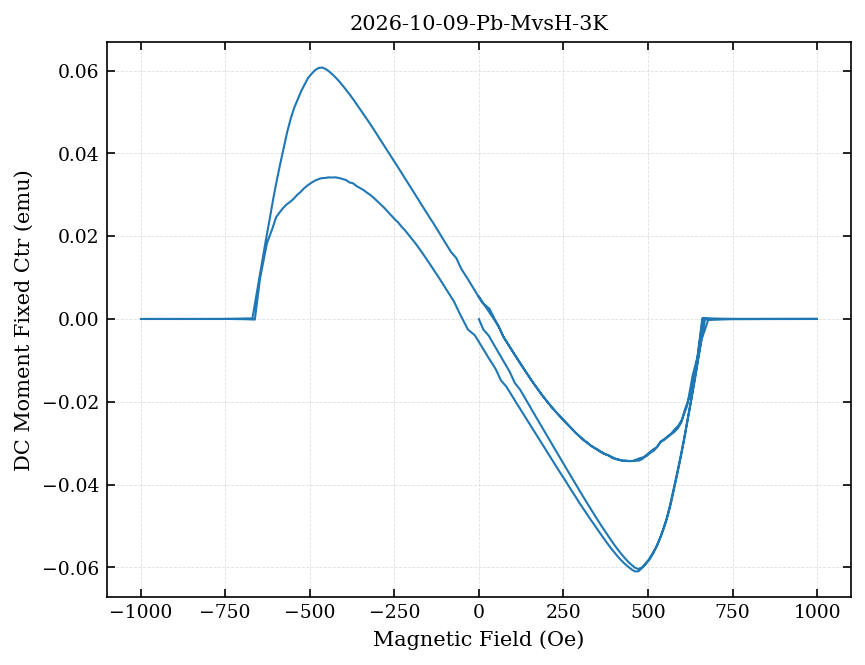

In [4]:
plt.plot(pb["Magnetic Field (Oe)"],pb["DC Moment Fixed Ctr (emu)"])
plt.title("2026-10-09-Pb-MvsH-3K")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.xlabel("Magnetic Field (Oe)")

### Current Plan for Data Analysis 
- we need a method for looping throught a set number of files
- easiest way is to make a folder for the data 
- and then loop throught the folder and get all the raw data 


In [5]:
# Source - https://stackoverflow.com/a/10378012
# Posted by anselm, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-15, License - CC BY-SA 4.0
# edited by ben thomposn

from pathlib import Path
runs = {}
pathlist = Path(
    r"C:\Users\olive\OneDrive - University of Bristol\Final Project\Data\Ollie_and_Ben\2026\10\Pv MvsH Various T"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs[run_number] = read_squid_file(str(path))
for run_number, data in runs.items():
    print(f"Run {run_number}")

Run 00001
Run 00002
Run 00003


In [6]:
field_column = "Magnetic Field (Oe)"
field_labels = {}

for run_number, dataframe in runs.items():
    mean_field = dataframe[field_column].mean()
    field_labels[run_number] = f"{mean_field:.0f} Oe"

In [7]:
for run_number, dataframe in runs.items():
    print(f"Run {run_number}")
    print(dataframe.head())
    print("="*80)

Run 00001
   Time Stamp (sec)  Temperature (K)  Magnetic Field (Oe)  Moment (emu)  \
0      4.001196e+09         3.000449             0.077638           NaN   
1      4.001196e+09         3.003144            13.162612           NaN   
2      4.001196e+09         2.995800            29.275466           NaN   
3      4.001196e+09         2.999037            39.320618           NaN   
4      4.001196e+09         3.001910            49.682293           NaN   

   M. Std. Err. (emu)  Transport Action  Center Position (mm)  \
0                 NaN                 6             31.809032   
1                 NaN                 6             31.809032   
2                 NaN                 6             31.809032   
3                 NaN                 6             31.809032   
4                 NaN                 6             31.809032   

   AC Susceptibility (emu/Oe)  AC Suscept. Std Err. (emu/Oe)  AC X' (emu/Oe)  \
0                         NaN                            NaN        

TypeError: string indices must be integers, not 'str'

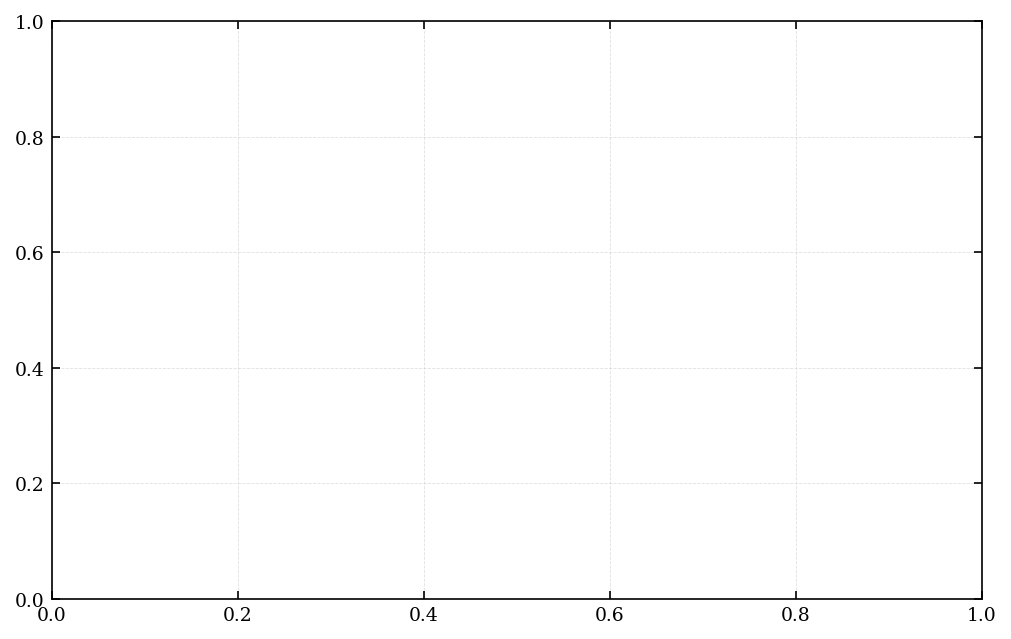

In [ ]:
# Git Copilot 5.6 Luna use to generate example code structure for fitting normal-state and transition regions of MvsT data. Code modified by Ollie Pentecost to suit Pb data.

# Extract one critical field Hc from each fixed-temperature M(H) sweep
from functions import determine_critical_field

temperature_column = "Temperature (K)"
moment_column = "DC Moment Fixed Ctr (emu)"
field_column = "Magnetic Field (Oe)"

fit_results = {}
temperature_list = []
hc_list = []

fig, ax = plt.subplots(figsize=(8, 5))
colors = plt.get_cmap("viridis", len(runs))

for plot_index, (run_number, dataframe) in enumerate(runs.items()):
    data = dataframe[[temperature_column, field_column, moment_column]].dropna()
    data = (field_column)
    #data = data.drop_duplicates(subset=field_column)


    # Each file is a field sweep at approximately one fixed temperature
    data = dataframe[
        [temperature_column, field_column, moment_column]
    ].dropna()

    # Each file is a field sweep at approximately one fixed temperature
    temperature = data[temperature_column].mean()

    field = data[field_column].to_numpy()
    moment = data[moment_column].to_numpy()
    field = data[field_column].to_numpy()
    moment = data[moment_column].to_numpy()

    # Determine Hc from all valid raw data using the moment-threshold criterion
    hc, field_pos, field_neg = determine_critical_field(data)

    colour = colors(plot_index)
    field_label = f"{temperature:.2f} K"

    temperature_list.append(temperature)
    hc_list.append(hc)
    fit_results[run_number] = {
        "Temperature (K)": temperature,
        "Hc (Oe)": hc,
        "Positive crossing (Oe)": field_pos,
        "Negative crossing (Oe)": field_neg,
    }

    ax.plot(
        field,
        moment,
        color=colour,
        linewidth=0.8,
        linestyle="-",
        label=field_label,
        zorder=2,
    )

    ax.scatter(
        [field_neg, field_pos],
        [0, 0],
        color=colour,
        edgecolor="black",
        zorder=5,
    )

    print(
        f"Run {run_number}: T = {temperature:.3f} K, "
        f"Hc = {hc:.2f} Oe"
    )

ax.set_title("Pb magnetic moment versus field at fixed temperatures")
ax.set_xlabel(field_column)
ax.set_ylabel(moment_column)
ax.legend(title="Temperature")
plt.show()

pd.DataFrame(fit_results).T

Tc0² = 53.65 ± 1.19 K²
Hc0 = 783.20 +/- 5.51 Oe
Tc0 = 7.32 +/- 0.08 K


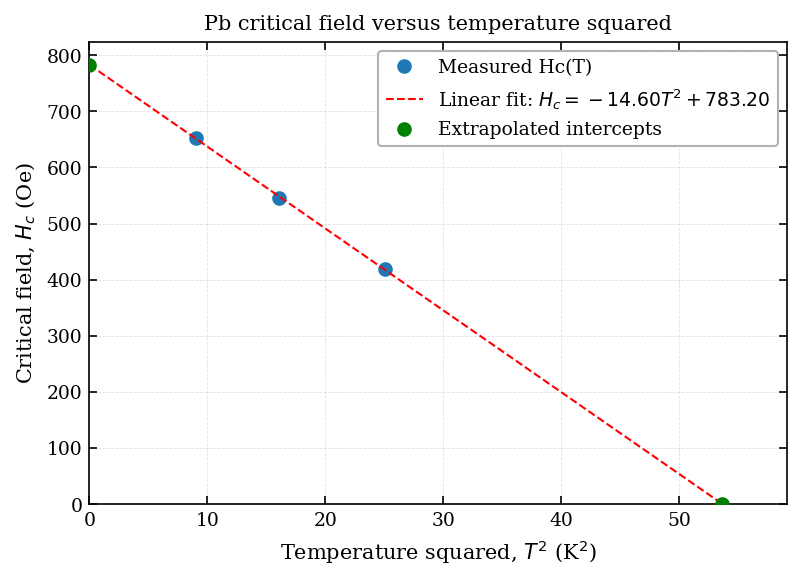

In [ ]:
# Fit the thermodynamic relation Hc(T) = Hc0 * [1 - (T / Tc0)^2]
# Rearranging gives a straight line: Hc = Hc0 - (Hc0 / Tc0^2) * T^2
temperature_array = np.array(temperature_list)
hc_array = np.array(hc_list)
temperature_squared = temperature_array ** 2

# Fit Hc as a linear function of T^2.
(m, c), cov = np.polyfit(
    temperature_squared,
    hc_array,
    1,
    cov=True,
)
m_err, c_err = np.sqrt(np.diag(cov))

# The y-intercept is Hc0. The x-intercept is Tc0^2
Hc0 = c
Tc0_squared = -c / m
Tc0 = np.sqrt(Tc0_squared)

# Propagate the fit uncertainties to Hc0 and Tc0
Hc0_err = c_err
Tc0_squared_err = Tc0_squared * np.sqrt(
    (m_err / m) ** 2 + (c_err / c) ** 2
)
Tc0_err = 0.5 * Tc0 * (Tc0_squared_err / Tc0_squared)

print(f"Tc0\u00b2 = {Tc0_squared:.2f} ± {Tc0_squared_err:.2f} K\u00b2")
print(f"Hc0 = {Hc0:.2f} +/- {Hc0_err:.2f} Oe")
print(f"Tc0 = {Tc0:.2f} +/- {Tc0_err:.2f} K")

x_fit = np.linspace(0, Tc0_squared * 1.05, 100)

plt.figure(figsize=(6, 4))
plt.plot(temperature_squared, hc_array, "o", label="Measured Hc(T)")
plt.plot(
    x_fit,
    m * x_fit + c,
    "r--",
    label=fr"Linear fit: $H_c = {m:.2f}T^2 + {c:.2f}$",
)
plt.scatter(
    [0, Tc0_squared],
    [Hc0, 0],
    color="green",
    zorder=3,
    label="Extrapolated intercepts",
)
plt.legend()
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.title("Pb critical field versus temperature squared")
plt.ylabel("Critical field, $H_c$ (Oe)")
plt.xlabel("Temperature squared, $T^2$ (K$^2$)")
plt.show()